<a href="https://colab.research.google.com/github/Singleeee/T2-IA-Classificacao/blob/main/Classification_corrigido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 2 — Classificação de subgêneros de Ficção Científica (versão corrigida)

**Principais mudanças em relação à versão anterior**
1. Análise exploratória completa (nº de classes, distribuição, duplicatas e **rótulos conflitantes**).
2. TF-IDF ajustado **apenas no treino** (sem vazamento de informação para validação/teste).
3. Árvore de Decisão **determinística** (sem sorteio de features), com busca em todas as features.
4. Regressão Logística com GD corrigida: regularização com escala `alpha` (não mais `1/C` sem normalização) e L1 via *proximal gradient* (soft-thresholding).
5. **Hiperparâmetros escolhidos na validação** (profundidade, `lr`, `alpha`); o teste é usado só no final.
6. Análise de consistência (30/60/90%) com subamostragem estratificada e hiperparâmetros fixos.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'science-fiction-books-subgenres' dataset.
Path to dataset files: /kaggle/input/science-fiction-books-subgenres


In [ ]:
import glob
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

%matplotlib inline
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

## 1. Dados e estudo introdutório

=== Qualidade dos dados ===
Linhas lidas (CSV):                      14974
Linhas com descrição válida:             14903
Duplicatas exatas (texto + subgênero):   30
Descrições em >1 subgênero:              2549  (6420 linhas, 43.1% do total)

>> REMOVER_AMBIGUOS=True: dataset final com 8470 registros.

=== Estudo introdutório ===
Instâncias: 8470 | Classes: 12


,qtd,%
subgenre,,
time_travel,986,11.64
aliens,937,11.06
steampunk,874,10.32
robots,835,9.86
cyberpunk,830,9.80
military,727,8.58
alternate_universe,651,7.69
alternate_history,615,7.26
apocalyptic,600,7.08


Razão de desbalanceamento (maior/menor classe): 2.38
Acurácia de um classificador que sempre prevê a classe majoritária: 0.116
Acurácia esperada ao acaso (1/K): 0.083

Tamanho do texto (palavras) — geral:
count    8470.00
mean      147.22
std        79.45
min         1.00
25%        94.00
50%       139.00
75%       186.00
max      1514.00

Tamanho médio do texto por classe:
                     mean   std
subgenre                       
aliens              169.2  81.7
alternate_history   165.0  94.6
alternate_universe  154.2  62.5
apocalyptic         147.7  77.2
cyberpunk           130.8  82.0
dystopia            148.0  64.0
hard                138.1  85.0
military            146.5  83.6
robots              114.5  68.9
space_opera         148.3  75.4
steampunk           149.3  61.8
time_travel         155.1  87.3

Exemplos (1 por classe):
[aliens] Starting over sucks.When we moved to West Virginia right before my senior year, I’d pretty much resigned myself to thick accents, dodgy inte

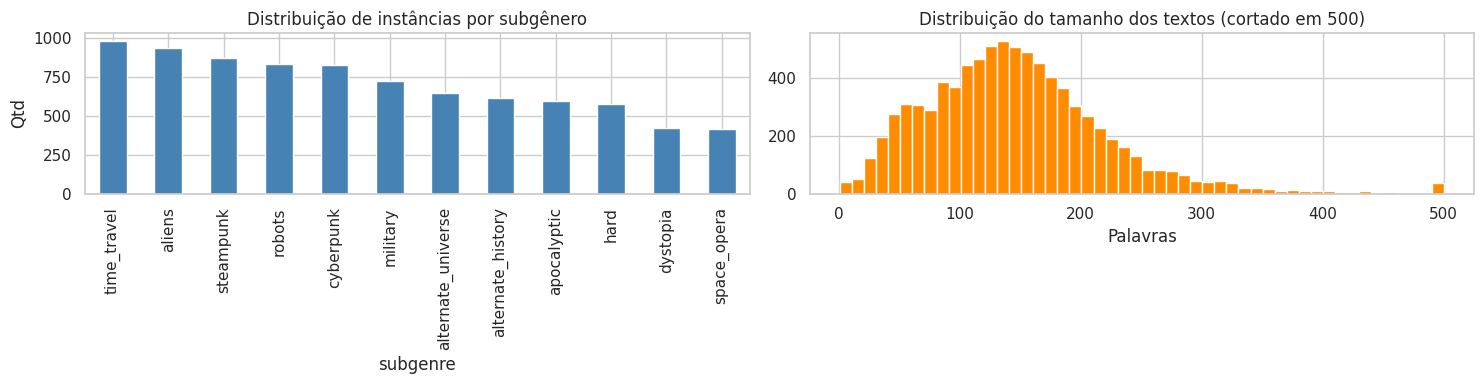

In [ ]:
# ---------------------------------------------------------------
# Configuração: o que fazer com descrições repetidas em vários subgêneros?
# True  -> remove duplicatas exatas e descrições "ambíguas" (mesmo texto, rótulos diferentes)
# False -> mantém tudo (o mesmo texto pode aparecer com rótulos diferentes; limita a acurácia)
# ---------------------------------------------------------------
REMOVER_AMBIGUOS = True

caminho_pasta = path  # caminho retornado pelo download do Kaggle (célula acima)
arquivos_csv = sorted(glob.glob(os.path.join(caminho_pasta, "**", "sf_*.csv"), recursive=True))

lista_dfs = []
for arquivo in arquivos_csv:
    df_temp = pd.read_csv(arquivo)
    df_temp['subgenre'] = os.path.basename(arquivo).replace('sf_', '').replace('.csv', '')
    lista_dfs.append(df_temp)

df_raw = pd.concat(lista_dfs, ignore_index=True)
df = df_raw.dropna(subset=['subgenre', 'Book_Description']).copy()
df['Book_Description'] = df['Book_Description'].astype(str).str.strip()
df = df[df['Book_Description'].str.len() > 0].reset_index(drop=True)

# ---- Qualidade dos rótulos: duplicatas e conflitos ----
n_sub_por_desc = df.groupby('Book_Description')['subgenre'].nunique()
desc_ambiguas = n_sub_por_desc[n_sub_por_desc > 1].index
dup_exatas = df.duplicated(subset=['Book_Description', 'subgenre']).sum()
linhas_ambiguas = df['Book_Description'].isin(desc_ambiguas).sum()

print("=== Qualidade dos dados ===")
print(f"Linhas lidas (CSV):                      {len(df_raw)}")
print(f"Linhas com descrição válida:             {len(df)}")
print(f"Duplicatas exatas (texto + subgênero):   {dup_exatas}")
print(f"Descrições em >1 subgênero:              {len(desc_ambiguas)}  ({linhas_ambiguas} linhas, "
      f"{100*linhas_ambiguas/len(df):.1f}% do total)")

if REMOVER_AMBIGUOS:
    df = df.drop_duplicates(subset=['Book_Description', 'subgenre'])
    df = df[~df['Book_Description'].isin(desc_ambiguas)].reset_index(drop=True)
    print(f"\n>> REMOVER_AMBIGUOS=True: dataset final com {len(df)} registros.")
else:
    print("\n>> REMOVER_AMBIGUOS=False: mantendo todos os registros (rótulos conflitantes presentes).")

# ---- Estudo introdutório ----
df['tamanho_texto'] = df['Book_Description'].str.split().str.len()
n_classes = df['subgenre'].nunique()
assert len(df) >= 2000 and n_classes >= 5, "Dataset não atende ao requisito (>=2000 instâncias e >=5 classes)"

print("\n=== Estudo introdutório ===")
print(f"Instâncias: {len(df)} | Classes: {n_classes}")
dist = df['subgenre'].value_counts().rename('qtd').to_frame()
dist['%'] = (100 * dist['qtd'] / len(df)).round(2)
display(dist)
print(f"Razão de desbalanceamento (maior/menor classe): {dist['qtd'].max()/dist['qtd'].min():.2f}")
print(f"Acurácia de um classificador que sempre prevê a classe majoritária: {dist['qtd'].max()/len(df):.3f}")
print(f"Acurácia esperada ao acaso (1/K): {1/n_classes:.3f}")

print("\nTamanho do texto (palavras) — geral:")
print(df['tamanho_texto'].describe().round(2).to_string())
print("\nTamanho médio do texto por classe:")
print(df.groupby('subgenre')['tamanho_texto'].agg(['mean', 'std']).round(1).to_string())

print("\nExemplos (1 por classe):")
for sg, g in df.groupby('subgenre'):
    print(f"[{sg}] {g['Book_Description'].iloc[0][:180]}...")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dist['qtd'].plot.bar(ax=axes[0], color='steelblue')
axes[0].set_title('Distribuição de instâncias por subgênero'); axes[0].set_ylabel('Qtd')
axes[1].hist(df['tamanho_texto'].clip(upper=500), bins=50, color='darkorange')
axes[1].set_title('Distribuição do tamanho dos textos (cortado em 500)'); axes[1].set_xlabel('Palavras')
plt.tight_layout(); plt.show()

## 2. Split 60/20/20 + TF-IDF (ajustado só no treino)

In [ ]:
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df['subgenre'])
textos = df['Book_Description'].values
N_CLASSES = len(label_encoder.classes_)

idx_all = np.arange(len(df))
idx_tv, idx_test = train_test_split(idx_all, test_size=0.20, random_state=SEED, stratify=y_all)
# 20% do total = 25% dos 80% restantes
idx_train, idx_val = train_test_split(idx_tv, test_size=0.25, random_state=SEED, stratify=y_all[idx_tv])

# TF-IDF: vocabulário e IDF aprendidos SOMENTE no treino
tfidf = TfidfVectorizer(max_features=2000, stop_words='english', ngram_range=(1, 2), dtype=np.float32)
X_train = tfidf.fit_transform(textos[idx_train]).toarray()
X_val   = tfidf.transform(textos[idx_val]).toarray()
X_test  = tfidf.transform(textos[idx_test]).toarray()
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

print("=== Divisão do Dataset (Split 60 / 20 / 20) ===")
for nome, yy in [('Treino', y_train), ('Validação', y_val), ('Teste', y_test)]:
    print(f"{nome:10s}: {len(yy):5d} amostras ({100*len(yy)/len(df):.1f}%)")
print(f"Features TF-IDF: {X_train.shape[1]} | Classes: {N_CLASSES}")

def metricas(y_true, y_pred):
    return {
        'Acurácia': accuracy_score(y_true, y_pred),
        'Precision (Macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Micro F1': f1_score(y_true, y_pred, average='micro'),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
    }

=== Divisão do Dataset (Split 60 / 20 / 20) ===
Treino    :  5082 amostras (60.0%)
Validação :  1694 amostras (20.0%)
Teste     :  1694 amostras (20.0%)
Features TF-IDF: 2000 | Classes: 12


## 3. Árvore de Decisão (implementada do zero, determinística)

In [ ]:
class Node:
    def __init__(self, value, n_samples, feature=None, threshold=None, left=None, right=None):
        self.value = value            # classe majoritária do nó (guardada em TODOS os nós)
        self.n_samples = n_samples
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right

    def is_leaf_node(self):
        return self.feature is None


class DecisionTreeFromScratch:
    """Árvore de decisão CART (gini/entropia), determinística.

    - Em cada nó avalia TODAS as features (sem sorteio).
    - Limiares candidatos por feature (calculados 1x no treino): 0 (presença/ausência da palavra)
      e quantis dos valores não-nulos do TF-IDF.
    - A busca é vetorizada: contagens por classe à esquerda do limiar via produto matricial.
    - Como a escolha do split em um nó não depende de max_depth, predict(X, max_depth=d)
      equivale a treinar uma árvore com max_depth=d (útil para a curva de aprendizado).
    """
    def __init__(self, criterion='gini', max_depth=10, min_samples_split=10,
                 min_samples_leaf=3, n_thresholds=4, min_gain=1e-7):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.n_thresholds = n_thresholds
        self.min_gain = min_gain
        self.root = None

    # ---------- impureza a partir de contagens (K x F) ----------
    def _impurity(self, counts, totals):
        p = counts / np.maximum(totals, 1)[None, :]
        if self.criterion == 'gini':
            return 1.0 - np.sum(p ** 2, axis=0)
        elif self.criterion == 'entropy':
            plogp = np.where(p > 0, p * np.log2(np.where(p > 0, p, 1.0)), 0.0)
            return -np.sum(plogp, axis=0)
        raise ValueError("criterion deve ser 'gini' ou 'entropy'")

    def _make_thresholds(self, X):
        n_feat, T = X.shape[1], self.n_thresholds
        thr = np.zeros((n_feat, T), dtype=np.float32)
        qs = np.linspace(0, 1, T + 1)[1:-1]
        if len(qs) > 0:
            for f in range(n_feat):
                nz = X[:, f]
                nz = nz[nz > 0]
                if nz.size:
                    thr[f, 1:] = np.quantile(nz, qs)
        return thr

    # ---------- treino ----------
    def fit(self, X, y, n_classes=None):
        self._X = np.asarray(X, dtype=np.float32)
        self._y = np.asarray(y, dtype=int)
        self.n_classes = int(n_classes) if n_classes is not None else int(self._y.max() + 1)
        self._Y = np.eye(self.n_classes, dtype=np.float32)[self._y]
        self.thresholds_ = self._make_thresholds(self._X)
        self.root = self._build_tree(np.arange(len(self._y)), depth=0)
        del self._X, self._y, self._Y
        return self

    def _build_tree(self, idx, depth):
        counts = np.bincount(self._y[idx], minlength=self.n_classes)
        node = Node(value=int(counts.argmax()), n_samples=len(idx))

        if (depth >= self.max_depth or len(idx) < self.min_samples_split
                or np.count_nonzero(counts) == 1):
            return node

        feat, thr = self._best_split(idx, counts)
        if feat is None:
            return node

        go_left = self._X[idx, feat] <= thr
        node.feature, node.threshold = feat, thr
        node.left = self._build_tree(idx[go_left], depth + 1)
        node.right = self._build_tree(idx[~go_left], depth + 1)
        return node

    def _best_split(self, idx, counts):
        Xs = self._X[idx]            # n x F
        Ys = self._Y[idx]            # n x K
        n = len(idx)
        parent = counts.astype(np.float32)
        parent_imp = self._impurity(parent[:, None], np.array([n]))[0]

        best_gain, best_feat, best_thr = self.min_gain, None, None
        for j in range(self.n_thresholds):
            thr_j = self.thresholds_[:, j]
            mask = (Xs <= thr_j).astype(np.float32)       # n x F
            left = Ys.T @ mask                            # K x F
            n_l = left.sum(axis=0)
            n_r = n - n_l
            valid = (n_l >= self.min_samples_leaf) & (n_r >= self.min_samples_leaf)
            if not valid.any():
                continue
            right = parent[:, None] - left
            child = (n_l * self._impurity(left, n_l) + n_r * self._impurity(right, n_r)) / n
            gain = np.where(valid, parent_imp - child, -np.inf)
            f = int(gain.argmax())
            if gain[f] > best_gain:
                best_gain, best_feat, best_thr = float(gain[f]), f, float(thr_j[f])
        return best_feat, best_thr

    # ---------- predição ----------
    def predict(self, X, max_depth=None):
        X = np.asarray(X, dtype=np.float32)
        limit = np.inf if max_depth is None else max_depth
        preds = np.empty(len(X), dtype=int)
        stack = [(self.root, np.arange(len(X)), 0)]
        while stack:
            node, idx, d = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf_node() or d >= limit:
                preds[idx] = node.value
                continue
            go_left = X[idx, node.feature] <= node.threshold
            stack.append((node.left, idx[go_left], d + 1))
            stack.append((node.right, idx[~go_left], d + 1))
        return preds

    def get_depth(self):
        def _d(n):
            return 0 if n is None or n.is_leaf_node() else 1 + max(_d(n.left), _d(n.right))
        return _d(self.root)

## 4. Regressão Logística (softmax) com Gradient Descent

In [ ]:
class LogisticRegressionGD:
    """Regressão logística multinomial treinada com gradient descent (full-batch).

    Objetivo:  CE_média(W) + alpha * R(W)
      - penalty=None         : R = 0
      - penalty='l2' (Ridge) : R = 0.5 * ||W||^2
      - penalty='l1' (Lasso) : R = ||W||_1                       (passo proximal / soft-thresholding)
      - penalty='elasticnet' : R = l1_ratio*||W||_1 + (1-l1_ratio)*0.5*||W||^2
    O viés (b) não é regularizado. O histórico guarda a cross-entropy SEM a penalidade
    (comparável entre treino/validação e entre regularizações).
    """
    def __init__(self, penalty=None, alpha=0.0, l1_ratio=0.5, lr=1.0, epochs=250):
        self.penalty = penalty
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.epochs = epochs

    @staticmethod
    def _softmax(Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        E = np.exp(Z)
        return E / E.sum(axis=1, keepdims=True)

    def _weights(self):
        if self.penalty == 'l2':
            return 0.0, self.alpha
        if self.penalty == 'l1':
            return self.alpha, 0.0
        if self.penalty == 'elasticnet':
            return self.alpha * self.l1_ratio, self.alpha * (1 - self.l1_ratio)
        return 0.0, 0.0

    @staticmethod
    def _ce(P, y):
        return float(-np.mean(np.log(P[np.arange(len(y)), y] + 1e-12)))

    def fit(self, X, y, X_val=None, y_val=None, n_classes=None):
        X = np.asarray(X, dtype=np.float32)
        m, n = X.shape
        K = int(n_classes) if n_classes is not None else int(np.max(y) + 1)
        Y = np.eye(K, dtype=np.float32)[y]
        l1_w, l2_w = self._weights()

        self.W = np.zeros((n, K), dtype=np.float32)
        self.b = np.zeros((1, K), dtype=np.float32)
        self.history_train_loss, self.history_val_loss = [], []
        self.history_train_acc, self.history_val_acc = [], []

        for _ in range(self.epochs):
            P = self._softmax(X @ self.W + self.b)
            self.history_train_loss.append(self._ce(P, y))
            self.history_train_acc.append(float(np.mean(P.argmax(1) == y)))
            if X_val is not None:
                Pv = self._softmax(X_val @ self.W + self.b)
                self.history_val_loss.append(self._ce(Pv, y_val))
                self.history_val_acc.append(float(np.mean(Pv.argmax(1) == y_val)))

            dW = X.T @ (P - Y) / m + l2_w * self.W
            db = (P - Y).sum(axis=0, keepdims=True) / m
            self.W -= self.lr * dW
            self.b -= self.lr * db
            if l1_w > 0:   # passo proximal do L1
                t = self.lr * l1_w
                self.W = np.sign(self.W) * np.maximum(np.abs(self.W) - t, 0.0)

        self.sparsity_ = float(np.mean(self.W == 0))
        return self

    def predict_proba(self, X):
        return self._softmax(np.asarray(X, dtype=np.float32) @ self.W + self.b)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

## 5. Seleção de hiperparâmetros na **validação**
O conjunto de teste não é usado nesta seção.

In [ ]:
# ---------- 5.1 Árvore de Decisão: profundidade ----------
D_MAX = 30
t0 = time.time()
tree_full = DecisionTreeFromScratch(max_depth=D_MAX).fit(X_train, y_train, n_classes=N_CLASSES)
print(f"Árvore treinada em {time.time()-t0:.1f}s | profundidade efetiva: {tree_full.get_depth()}")

depths = list(range(1, D_MAX + 1))
ad_rows = []
for d in depths:
    p_tr, p_va = tree_full.predict(X_train, max_depth=d), tree_full.predict(X_val, max_depth=d)
    ad_rows.append({'max_depth': d,
                    'Acc Treino': accuracy_score(y_train, p_tr), 'Acc Val': accuracy_score(y_val, p_va),
                    'F1-Macro Treino': f1_score(y_train, p_tr, average='macro'),
                    'F1-Macro Val': f1_score(y_val, p_va, average='macro')})
df_ad = pd.DataFrame(ad_rows)
BEST_DEPTH = int(df_ad.loc[df_ad['F1-Macro Val'].idxmax(), 'max_depth'])
print(f"Melhor max_depth (F1-macro na validação): {BEST_DEPTH}")
display(df_ad.round(4))

Árvore treinada em 21.2s | profundidade efetiva: 30
Melhor max_depth (F1-macro na validação): 29


,max_depth,Acc Treino,Acc Val,F1-Macro Treino,F1-Macro Val
0,1,0.1543,0.1523,0.0632,0.0613
1,2,0.2046,0.1989,0.1055,0.1003
2,3,0.2336,0.2196,0.1587,0.1431
3,4,0.2464,0.2355,0.1846,0.1710
4,5,0.2605,0.2450,0.2122,0.1929
5,6,0.2651,0.2456,0.2123,0.1889
6,7,0.2873,0.2656,0.2184,0.1940
7,8,0.3036,0.2774,0.2564,0.2285
8,9,0.3139,0.2798,0.2615,0.2191
9,10,0.3272,0.2893,0.2804,0.2342


In [ ]:
# ---------- 5.2 LR-GD: taxa de aprendizado (sem regularização) ----------
EPOCHS = 250
LRS = [1, 5, 20, 50]
lr_rows, lr_models = [], {}
for lr_ in LRS:
    t0 = time.time()
    m_ = LogisticRegressionGD(penalty=None, lr=lr_, epochs=EPOCHS).fit(
        X_train, y_train, X_val, y_val, n_classes=N_CLASSES)
    pv = m_.predict(X_val)
    lr_rows.append({'lr': lr_, 'Loss Treino (final)': m_.history_train_loss[-1],
                    'Loss Val (final)': m_.history_val_loss[-1],
                    'Acc Val': accuracy_score(y_val, pv), 'F1-Macro Val': f1_score(y_val, pv, average='macro'),
                    'tempo (s)': time.time() - t0})
    lr_models[lr_] = m_
df_lr = pd.DataFrame(lr_rows)
BEST_LR = float(df_lr.loc[df_lr['F1-Macro Val'].idxmax(), 'lr'])
print(f"Melhor lr (F1-macro na validação): {BEST_LR}")
display(df_lr.round(4))

Melhor lr (F1-macro na validação): 20.0


,lr,Loss Treino (final),Loss Val (final),Acc Val,F1-Macro Val,tempo (s)
0,1,2.1408,2.1882,0.4681,0.3436,10.3467
1,5,1.4546,1.6369,0.6051,0.5264,8.9309
2,20,0.8051,1.2293,0.6440,0.6046,9.5200
3,50,0.5599,1.2810,0.6039,0.5605,10.2807


In [ ]:
# ---------- 5.3 LR-GD: força da regularização (alpha) para Ridge, Lasso e Elastic Net ----------
ALPHAS = [1e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3]
penalidades = [('Ridge (L2)', 'l2'), ('Lasso (L1)', 'l1'), ('Elastic Net', 'elasticnet')]

busca_rows = []
melhores = {}   # nome -> (F1 val, alpha, modelo)
for nome, pen in penalidades:
    for a in ALPHAS:
        m_ = LogisticRegressionGD(penalty=pen, alpha=a, l1_ratio=0.5, lr=BEST_LR, epochs=EPOCHS).fit(
            X_train, y_train, X_val, y_val, n_classes=N_CLASSES)
        pv = m_.predict(X_val)
        f1v = f1_score(y_val, pv, average='macro')
        busca_rows.append({'Regularização': nome, 'alpha': f'{a:g}', 'Loss Treino': m_.history_train_loss[-1],
                           'Loss Val': m_.history_val_loss[-1], 'Acc Val': accuracy_score(y_val, pv),
                           'F1-Macro Val': f1v, '% pesos zerados': 100 * m_.sparsity_})
        if nome not in melhores or f1v > melhores[nome][0]:
            melhores[nome] = (f1v, a, m_)

df_busca = pd.DataFrame(busca_rows)
display(df_busca.round(4))

modelos_lr = {'Sem regularização': lr_models[BEST_LR]}
alphas_escolhidos = {'Sem regularização': 0.0}
for nome, _ in penalidades:
    modelos_lr[nome] = melhores[nome][2]
    alphas_escolhidos[nome] = melhores[nome][1]
print("alpha escolhido (validação):", {k: v for k, v in alphas_escolhidos.items() if k != 'Sem regularização'})

,Regularização,alpha,Loss Treino,Loss Val,Acc Val,F1-Macro Val,% pesos zerados
0,Ridge (L2),1e-06,0.8065,1.2301,0.6446,0.6051,0.0000
1,Ridge (L2),1e-05,0.8195,1.2375,0.6446,0.6041,0.0000
2,Ridge (L2),3e-05,0.8482,1.2542,0.6464,0.6056,0.0000
3,Ridge (L2),0.0001,0.9462,1.3134,0.6476,0.6026,0.0000
4,Ridge (L2),0.0003,1.1884,1.4705,0.6370,0.5834,0.0000
5,Ridge (L2),0.001,1.6856,1.8316,0.5006,0.4352,0.0000
6,Lasso (L1),1e-06,0.8085,1.2306,0.6434,0.6038,0.0375
7,Lasso (L1),1e-05,0.8406,1.2428,0.6423,0.6009,5.2958
8,Lasso (L1),3e-05,0.9160,1.2712,0.6340,0.5924,25.4042
9,Lasso (L1),0.0001,1.1449,1.3724,0.6116,0.5695,74.2542


alpha escolhido (validação): {'Ridge (L2)': 3e-05, 'Lasso (L1)': 1e-06, 'Elastic Net': 1e-06}


## 6. Curvas de aprendizado (treino × validação)

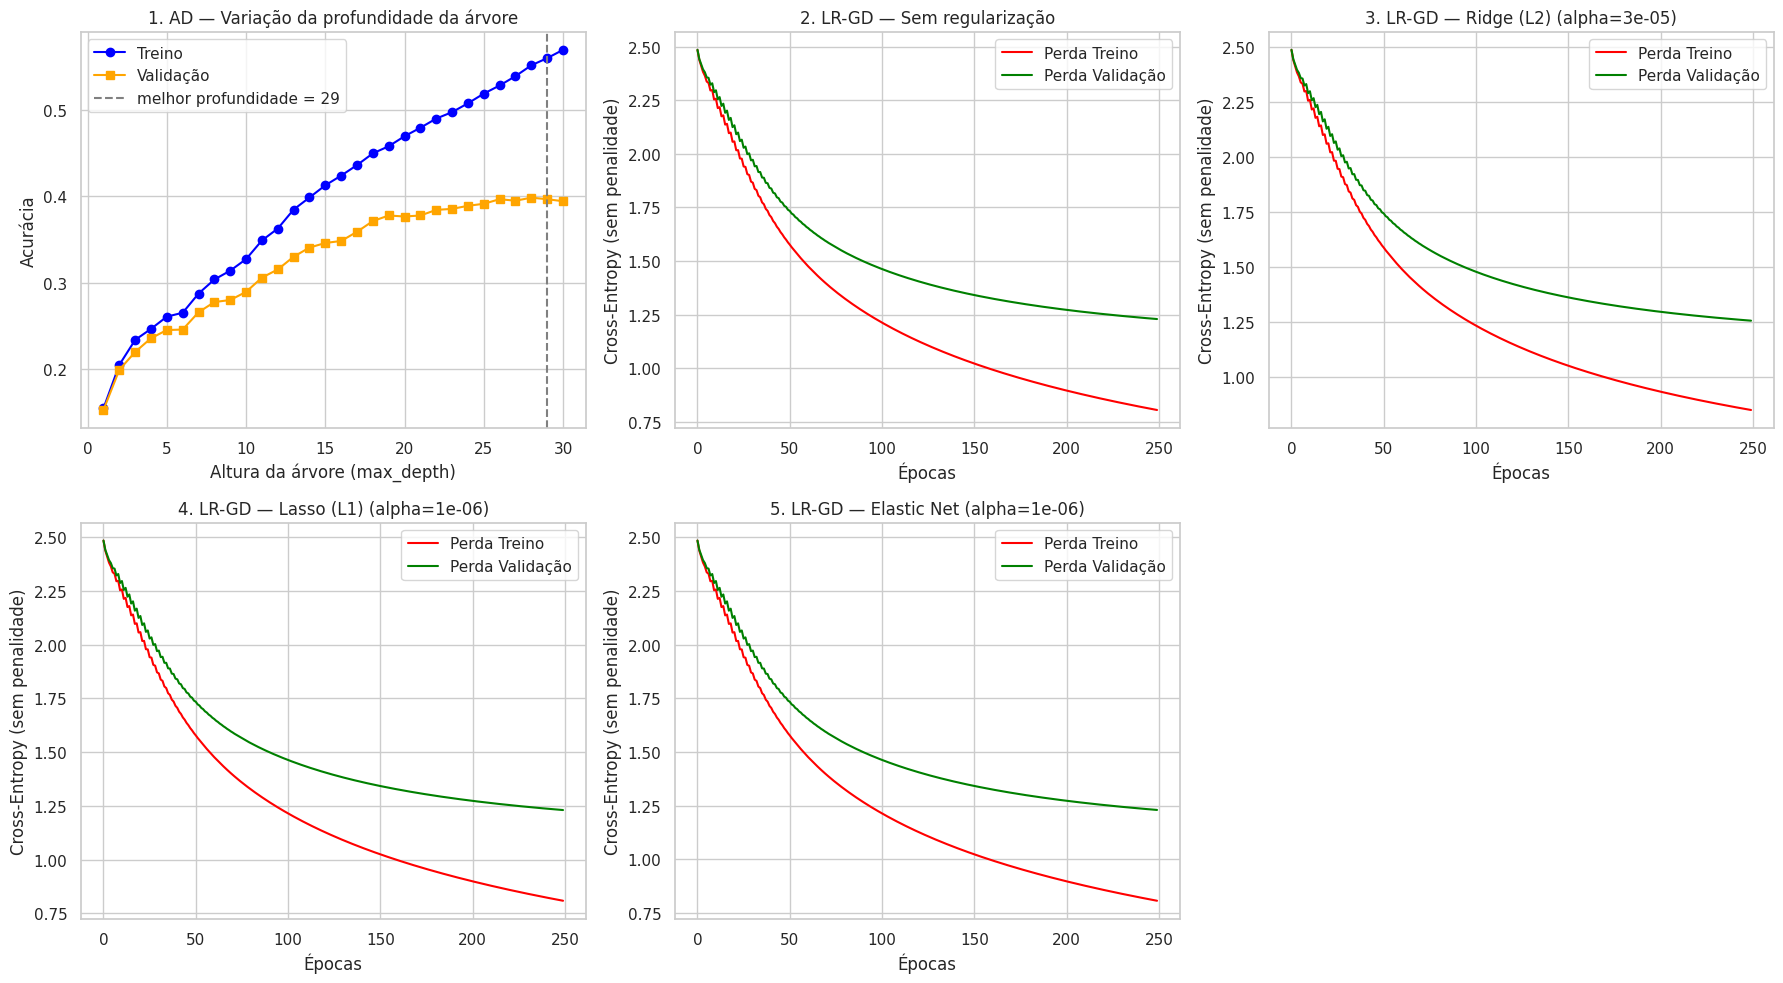

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# 1. Árvore de Decisão — aumento da profundidade
axes[0].plot(df_ad['max_depth'], df_ad['Acc Treino'], 'o-', label='Treino', color='blue')
axes[0].plot(df_ad['max_depth'], df_ad['Acc Val'], 's-', label='Validação', color='orange')
axes[0].axvline(BEST_DEPTH, ls='--', color='gray', label=f'melhor profundidade = {BEST_DEPTH}')
axes[0].set_title('1. AD — Variação da profundidade da árvore')
axes[0].set_xlabel('Altura da árvore (max_depth)'); axes[0].set_ylabel('Acurácia'); axes[0].legend()

# 2-5. LR-GD — perda por época
for i, (nome, mod) in enumerate(modelos_lr.items(), start=1):
    ax = axes[i]
    ax.plot(mod.history_train_loss, label='Perda Treino', color='red')
    ax.plot(mod.history_val_loss, label='Perda Validação', color='green')
    sufixo = '' if nome == 'Sem regularização' else f' (alpha={alphas_escolhidos[nome]:g})'
    ax.set_title(f'{i+1}. LR-GD — {nome}{sufixo}')
    ax.set_xlabel('Épocas'); ax.set_ylabel('Cross-Entropy (sem penalidade)'); ax.legend()

fig.delaxes(axes[5])
plt.tight_layout(); plt.show()

## 7. Análise de consistência (30%, 60% e 90% do conjunto de treino)
Hiperparâmetros fixos (escolhidos na validação); cada fração é uma **subamostra estratificada** do treino (60% do total).

LR-GD regularizada usada na consistência: Ridge (L2) (alpha=3e-05)
=== Tabela de Análise de Consistência ===


,Modelo,Fração,N treino,Acc Treino,Acc Val,F1-Macro Treino,F1-Macro Val
0,AD (max_depth=29),30%,1524,0.5781,0.3571,0.6009,0.3422
1,LR-GD sem regularização,30%,1524,0.9895,0.5897,0.9894,0.5455
2,LR-GD Ridge (L2),30%,1524,0.9888,0.5891,0.9886,0.5450
3,AD (max_depth=29),60%,3049,0.5779,0.3819,0.5859,0.3596
4,LR-GD sem regularização,60%,3049,0.9164,0.6234,0.9105,0.5860
5,LR-GD Ridge (L2),60%,3049,0.9137,0.6240,0.9076,0.5837
6,AD (max_depth=29),90%,4573,0.5565,0.3784,0.5428,0.3521
7,LR-GD sem regularização,90%,4573,0.8485,0.6434,0.8408,0.6029
8,LR-GD Ridge (L2),90%,4573,0.8458,0.6446,0.8378,0.6032


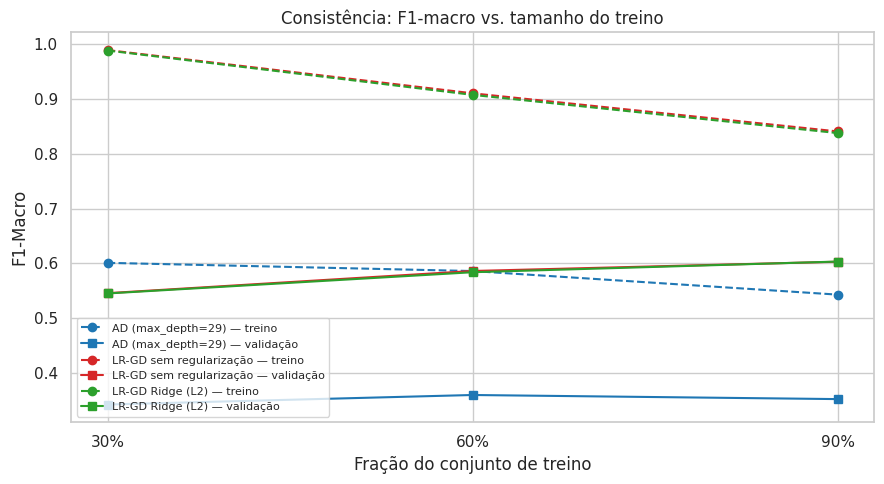

In [ ]:
melhor_reg_nome = max([n for n, _ in penalidades], key=lambda n: melhores[n][0])
melhor_reg_pen = dict(penalidades)[melhor_reg_nome]
melhor_reg_alpha = alphas_escolhidos[melhor_reg_nome]
print(f"LR-GD regularizada usada na consistência: {melhor_reg_nome} (alpha={melhor_reg_alpha:g})")

fracs = [0.3, 0.6, 0.9]
rows = []
for f in fracs:
    sub, _ = train_test_split(np.arange(len(y_train)), train_size=f, random_state=SEED, stratify=y_train)
    Xs, ys = X_train[sub], y_train[sub]

    modelos = {
        f'AD (max_depth={BEST_DEPTH})': DecisionTreeFromScratch(max_depth=BEST_DEPTH).fit(Xs, ys, n_classes=N_CLASSES),
        'LR-GD sem regularização': LogisticRegressionGD(penalty=None, lr=BEST_LR, epochs=EPOCHS).fit(Xs, ys, n_classes=N_CLASSES),
        f'LR-GD {melhor_reg_nome}': LogisticRegressionGD(penalty=melhor_reg_pen, alpha=melhor_reg_alpha,
                                                         lr=BEST_LR, epochs=EPOCHS).fit(Xs, ys, n_classes=N_CLASSES),
    }
    for nome, mod in modelos.items():
        ptr, pva = mod.predict(Xs), mod.predict(X_val)
        rows.append({'Modelo': nome, 'Fração': f"{int(f*100)}%", 'N treino': len(ys),
                     'Acc Treino': accuracy_score(ys, ptr), 'Acc Val': accuracy_score(y_val, pva),
                     'F1-Macro Treino': f1_score(ys, ptr, average='macro'),
                     'F1-Macro Val': f1_score(y_val, pva, average='macro')})

df_consistencia = pd.DataFrame(rows)
print("=== Tabela de Análise de Consistência ===")
display(df_consistencia.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
cores = dict(zip(df_consistencia['Modelo'].unique(), ['tab:blue', 'tab:red', 'tab:green']))
for nome, g in df_consistencia.groupby('Modelo', sort=False):
    ax.plot(g['Fração'], g['F1-Macro Treino'], '--o', color=cores[nome], label=f'{nome} — treino')
    ax.plot(g['Fração'], g['F1-Macro Val'], '-s', color=cores[nome], label=f'{nome} — validação')
ax.set_xlabel('Fração do conjunto de treino'); ax.set_ylabel('F1-Macro')
ax.set_title('Consistência: F1-macro vs. tamanho do treino'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Avaliação final no conjunto de **teste**
Modelos treinados no conjunto de treino (60%) com os hiperparâmetros escolhidos na validação.

In [ ]:
modelos_finais = {
    f'Árvore de Decisão (max_depth={BEST_DEPTH})': ('ad', None),
    'LR-GD Sem Regularização': ('lr', modelos_lr['Sem regularização']),
    f"LR-GD Ridge (L2, alpha={alphas_escolhidos['Ridge (L2)']:g})": ('lr', modelos_lr['Ridge (L2)']),
    f"LR-GD Lasso (L1, alpha={alphas_escolhidos['Lasso (L1)']:g})": ('lr', modelos_lr['Lasso (L1)']),
    f"LR-GD Elastic Net (alpha={alphas_escolhidos['Elastic Net']:g})": ('lr', modelos_lr['Elastic Net']),
}

def prever(tipo, mod, X):
    return tree_full.predict(X, max_depth=BEST_DEPTH) if tipo == 'ad' else mod.predict(X)

res, preds_dict, f1_val_dict = [], {}, {}
for nome, (tipo, mod) in modelos_finais.items():
    preds = prever(tipo, mod, X_test)
    preds_dict[nome] = preds
    f1_val_dict[nome] = f1_score(y_val, prever(tipo, mod, X_val), average='macro')
    res.append({'Modelo': nome, **metricas(y_test, preds)})

df_metricas = pd.DataFrame(res)
print("=== Consolidação Final no Conjunto de Teste ===")
display(df_metricas.round(4))
print("Obs.: em classificação multiclasse com uma classe por instância, Micro F1 = Acurácia.")

=== Consolidação Final no Conjunto de Teste ===


,Modelo,Acurácia,Precision (Macro),Recall (Macro),Micro F1,Macro F1
0,Árvore de Decisão (max_depth=29),0.4050,0.4466,0.3720,0.4050,0.3839
1,LR-GD Sem Regularização,0.6494,0.6447,0.6191,0.6494,0.6245
2,"LR-GD Ridge (L2, alpha=3e-05)",0.6494,0.6501,0.6184,0.6494,0.6248
3,"LR-GD Lasso (L1, alpha=1e-06)",0.6499,0.6452,0.6194,0.6499,0.6248
4,LR-GD Elastic Net (alpha=1e-06),0.6494,0.6448,0.6191,0.6494,0.6245


Obs.: em classificação multiclasse com uma classe por instância, Micro F1 = Acurácia.


Modelos selecionados para as matrizes de confusão: ['LR-GD Ridge (L2, alpha=3e-05)', 'LR-GD Sem Regularização', 'LR-GD Elastic Net (alpha=1e-06)']


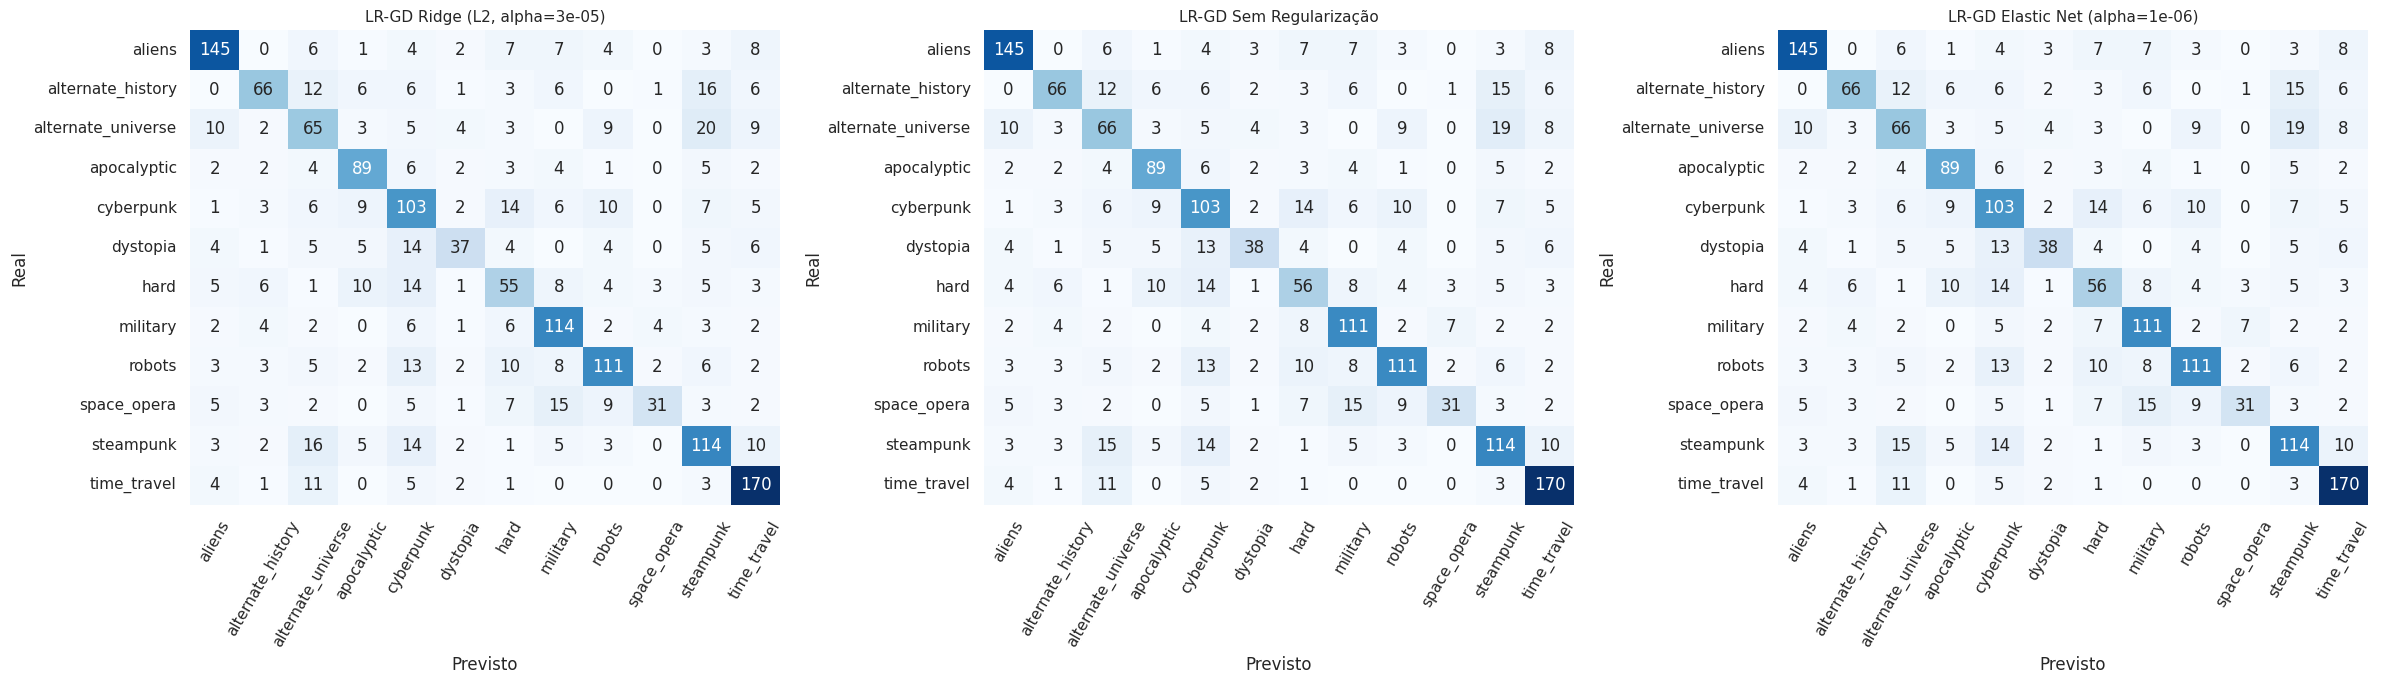

In [ ]:
# Os 3 modelos mais significativos = maiores F1-macro na VALIDAÇÃO (sem olhar o teste)
top_3_modelos = sorted(f1_val_dict, key=f1_val_dict.get, reverse=True)[:3]
print("Modelos selecionados para as matrizes de confusão:", top_3_modelos)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, m_nome in zip(axes, top_3_modelos):
    cm = confusion_matrix(y_test, preds_dict[m_nome], labels=range(N_CLASSES))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    ax.set_title(f'{m_nome}', fontsize=11)
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real')
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()